## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements, error_mshred, error_mshred_2
import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

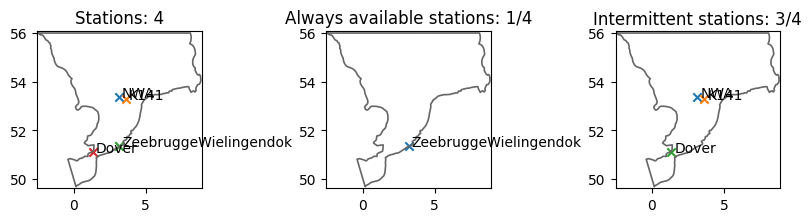

H shape: torch.Size([32064, 8533])
U shape: torch.Size([32064, 8533])
V shape: torch.Size([32064, 8533])
Measurements shape: torch.Size([32064, 4])
Always-available measurements shape: torch.Size([32064, 1])


In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# read datasets
ds = dfs.read(time = slice("2022-01-01", "2023-10-30"))
dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

del dfs

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
hf = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]
alllist = [s for s in alllist if s.name in hf]

stations = []
available_stations = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        available_stations.append(alllist[i])
    else:
        intermittent.append(alllist[i])

# extract water level measurements for all stations
measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

fig, axs = plt.subplots(1,3, figsize = (8,3))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")
plt.tight_layout()
plt.show()

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in available_stations]
measurements_av = measurements[:, av_indices]

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)
print("Always-available measurements shape:", measurements_av.shape)

# free memory
del dsH, dsU, dsV

## Hyperparameters

In [4]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 50           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3              # number of encoder layers
HIDDEN_SIZE = 64                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 96            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [100]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## only available sensors

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements_av)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1] 
nn_output_shape = train_dataset[0][1].shape[0]  
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([25651, 24, 1]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 24, 1]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 24, 1]) -> torch.Size([3207, 120])

Input shape for the model: 1
Output shape for the model: 120


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

NAME = "models_accumulation/normal.pt"

# save model
if not Path("models_accumulation").exists():
    Path("models_accumulation").mkdir(parents=True, exist_ok=True)
# if it is not already saved, save the model
if not Path(NAME).exists():

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    )

    torch.save(mshred.state_dict(), NAME)

    # PLOT TRAINING CURVES
    plot_training_curves(train_errors, valid_errors)

else:
    # Load the model if it is already saved
    mshred.load_state_dict(torch.load(NAME))
    print(f"Loaded model from {NAME}")


Loaded model from models_accumulation/normal.pt


In [7]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

del engine, mshred, model_args

In [8]:
M_rmse_baseline, M_nmae_baseline = error_mshred_2(test_reconstruction, ds)
print("mSHRED RMSE shape:", M_rmse_baseline.shape)
print("mSHRED NMAE shape:", M_nmae_baseline.shape)

mSHRED RMSE shape: (3207, 3)
mSHRED NMAE shape: (3207, 3)


## Masking x2 channels + MHSA masking

In [9]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 25037

Data shapes after preparation:
Train:	 torch.Size([25651, 24, 4]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 24, 4]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 24, 4]) -> torch.Size([3207, 120])

Input shape for the model: 4
Output shape for the model: 120


In [10]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

NAME = "models_accumulation/masked.pt"

# save model
if not Path("models_accumulation").exists():
    Path("models_accumulation").mkdir(parents=True, exist_ok=True)
# if it is not already saved, save the model
if not Path(NAME).exists():

    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
    )

    torch.save(mshred.state_dict(), NAME)

    # PLOT TRAINING CURVES
    plot_training_curves(train_errors, valid_errors)

else:
    # Load the model if it is already saved
    mshred.load_state_dict(torch.load(NAME))
    print(f"Loaded model from {NAME}")



Loaded model from models_accumulation/masked.pt


In [11]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

del engine, mshred, model_args

In [12]:
M_rmse_t3g, M_nmae_t3g = error_mshred_2(test_reconstruction, ds)
print("mSHRED RMSE shape:", M_rmse_t3g.shape)
print("mSHRED NMAE shape:", M_nmae_t3g.shape)

mSHRED RMSE shape: (3207, 3)
mSHRED NMAE shape: (3207, 3)


In [16]:
print(M_nmae_baseline.mean(axis=0))
print(M_nmae_t3g.mean(axis=0))

# put the mean errors into a dataframe for saving as CSV
csv = pd.DataFrame({
    "mSHRED baseline RMSE mean": M_rmse_baseline.mean(axis=0).mean(),
    "mSHRED baseline NMAE mean": M_nmae_baseline.mean(axis=0).mean(),
    "mSHRED masked RMSE mean": M_rmse_t3g.mean(axis=0).mean(),
    "mSHRED masked NMAE mean": M_nmae_t3g.mean(axis=0).mean(),
    "mSHRED baseline RMSE": M_rmse_baseline.mean(axis=0),
    "mSHRED baseline NMAE": M_nmae_baseline.mean(axis=0),
    "mSHRED masked RMSE": M_rmse_t3g.mean(axis=0),
    "mSHRED masked NMAE": M_nmae_t3g.mean(axis=0),  
})
#create the csv file name based on the model name
NAME = NAME.split("/")[-1].split(".")[0]
#open the old csv file for writing
csv.to_csv(f"models_accumulation/results.csv", index=False)

[0.01472637 0.01430484 0.01128394]
[0.01113423 0.01312243 0.00977117]


## New plot

Surface elevation cumulative RMSE % change: -21.23%
U velocity cumulative RMSE % change: -7.84%
V velocity cumulative RMSE % change: -12.60%
Surface elevation cumulative NMAE % change: -24.39%
U velocity cumulative NMAE % change: -8.27%
V velocity cumulative NMAE % change: -13.41%


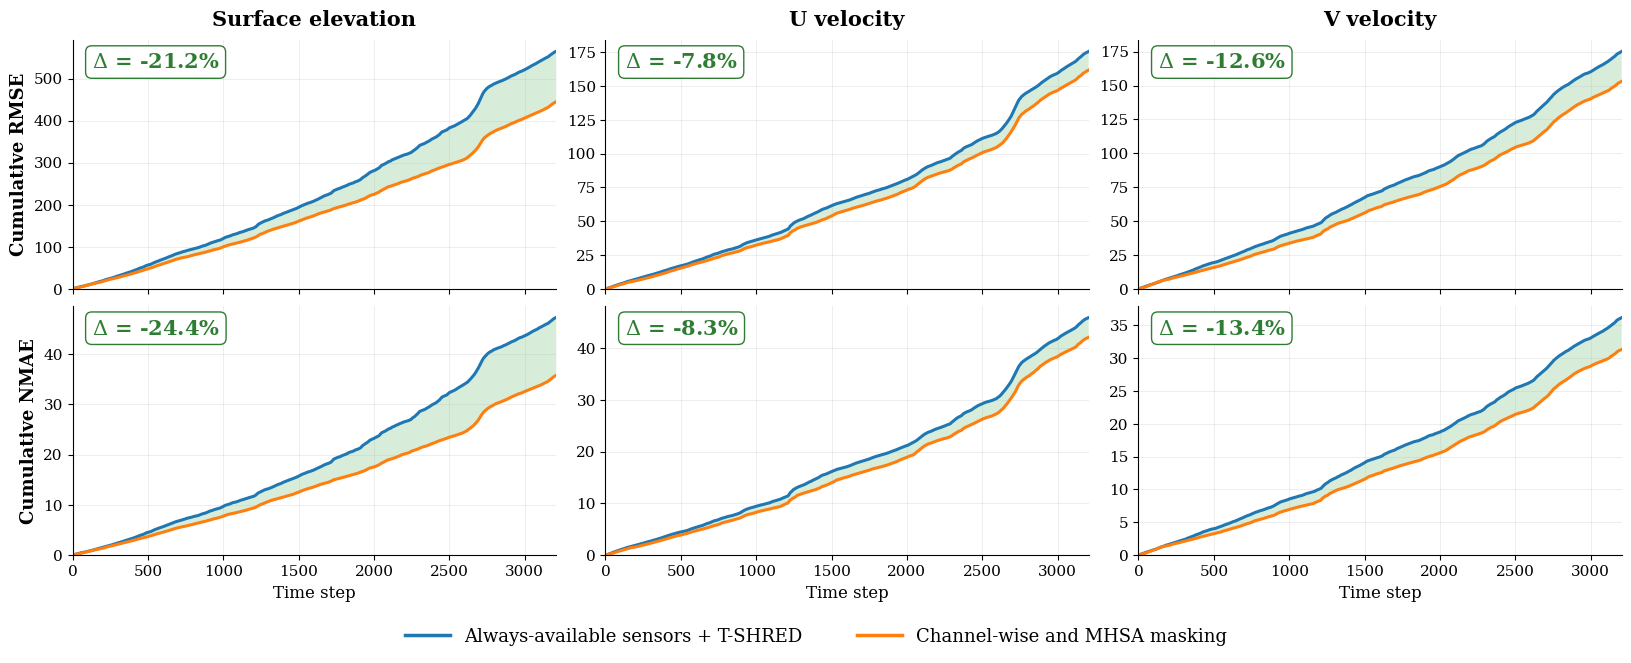

In [17]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "legend.frameon": False,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

C_BASE = "#1f77b4"
C_T3G = "#ff7f0e"
C_DELTA_GOOD = "#2e7d32"
C_DELTA_BAD = "#c62828"

METHOD_NAME = "Channel-wise and MHSA masking"
BASELINE_NAME = "Always-available sensors + T-SHRED"

titles = ["Surface elevation", "U velocity", "V velocity"]

# ------------------------------------------------------------------
# Cumulative errors
# ------------------------------------------------------------------
cum_rmse_baseline = np.cumsum(M_rmse_baseline, axis=0)
cum_rmse_t3g = np.cumsum(M_rmse_t3g, axis=0)

cum_nmae_baseline = np.cumsum(M_nmae_baseline, axis=0)
cum_nmae_t3g = np.cumsum(M_nmae_t3g, axis=0)

rows = [
    ("Cumulative RMSE", cum_rmse_baseline, cum_rmse_t3g),
    ("Cumulative NMAE", cum_nmae_baseline, cum_nmae_t3g),
]

# ------------------------------------------------------------------
# Final-time divergence rate (%)
# Negative = T.3.G improves over baseline
# ------------------------------------------------------------------
eps = 1e-12

final_cum_base_rmse = cum_rmse_baseline[-1]
final_cum_t3g_rmse = cum_rmse_t3g[-1]

divergence_cum_rmse_pct = (
    100
    * (final_cum_t3g_rmse - final_cum_base_rmse)
    / (final_cum_base_rmse + eps)
)

final_cum_base_nmae = cum_nmae_baseline[-1]
final_cum_t3g_nmae = cum_nmae_t3g[-1]

divergence_cum_nmae_pct = (
    100
    * (final_cum_t3g_nmae - final_cum_base_nmae)
    / (final_cum_base_nmae + eps)
)

for name, val in zip(titles, divergence_cum_rmse_pct):
    print(f"{name} cumulative RMSE % change: {val:.2f}%")

for name, val in zip(titles, divergence_cum_nmae_pct):
    print(f"{name} cumulative NMAE % change: {val:.2f}%")

divergence_pct = [
    divergence_cum_rmse_pct,
    divergence_cum_nmae_pct,
]

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
n_steps = rows[0][1].shape[0]
t = np.arange(n_steps)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16.2, 6.0),
    sharex=True,
    constrained_layout=True,
)

for r, (row_label, base, t3g) in enumerate(rows):
    for c in range(3):
        ax = axes[r, c]

        b = base[:, c]
        g = t3g[:, c]

        ax.plot(
            t, b,
            color=C_BASE,
            lw=2.2,
            label=BASELINE_NAME,
        )

        ax.plot(
            t, g,
            color=C_T3G,
            lw=2.2,
            label=METHOD_NAME,
        )

        # Shaded area: accumulated gain / worsening
        ax.fill_between(
            t, g, b,
            where=(b >= g),
            color="#66bb6a",
            alpha=0.25,
            lw=0,
        )

        ax.fill_between(
            t, g, b,
            where=(b < g),
            color="red",
            alpha=0.12,
            lw=0,
        )

        # Final-time percentage change
        d = divergence_pct[r][c]
        better = d < 0
        delta_color = C_DELTA_GOOD if better else C_DELTA_BAD

        ax.text(
            0.04, 0.95,
            f"$\\Delta$ = {d:+.1f}%",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=15,
            fontweight="bold",
            color=delta_color,
            bbox=dict(
                boxstyle="round,pad=0.3",
                fc="white",
                ec=delta_color,
                lw=1.0,
            ),
        )

        # Cosmetics
        ax.set_xlim(0, n_steps - 1)
        ax.set_ylim(bottom=0)
        ax.grid(True, alpha=0.25, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        ax.ticklabel_format(
            axis="y",
            style="sci",
            scilimits=(-3, 4),
        )

        if r == 0:
            ax.set_title(titles[c], pad=10)

        if r == 1:
            ax.set_xlabel("Time step")

        if c == 0:
            ax.set_ylabel(
                row_label,
                fontweight="bold",
                fontsize=13,
            )

# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------
handles = [
    Line2D(
        [0], [0],
        color=C_BASE,
        lw=2.5,
        label=BASELINE_NAME,
    ),
    Line2D(
        [0], [0],
        color=C_T3G,
        lw=2.5,
        label=METHOD_NAME,
    ),
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.01),
    fontsize=13,
    columnspacing=3.0,
    handlelength=2.5,
)

# ------------------------------------------------------------------
# Save and show
# ------------------------------------------------------------------
fig.savefig(
    "HYDRO_5_error_accumulation.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()
